<a href="https://colab.research.google.com/github/jiroammarwafi/244107020190-ML/blob/main/k_means.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import Normalizer, StandardScaler
import time
import tracemalloc
from sklearn.metrics import silhouette_score

In [ ]:
file_path = "Sleep_health_and_lifestyle_dataset.csv"
df = pd.read_csv(file_path)

df_clean = df.drop(columns=["Person ID"])
df_clean["Sleep Disorder"] = df_clean["Sleep Disorder"].fillna("None")
df_clean["BMI Category"] = df_clean["BMI Category"].replace(
    {"Normal Weight": "Normal"}
)

df_clean[["Systolic_BP", "Diastolic_BP"]] = (
    df_clean["Blood Pressure"].str.split("/", expand=True).astype(int)
)
df_clean = df_clean.drop(columns=["Blood Pressure"])

categorical_cols = ["Gender", "Occupation", "BMI Category", "Sleep Disorder"]
df_encoded = pd.get_dummies(
    df_clean, columns=categorical_cols, drop_first=False, dtype=int
)

Baris 1 — file_path = "Sleep_health_and_lifestyle_dataset.csv" : Menyimpan nama atau jalur file dataset CSV ke dalam variabel file_path.

Baris 2 — df = pd.read_csv(file_path) : Membaca file CSV menggunakan pustaka pandas dan memuatnya ke dalam bentuk tabel DataFrame bernama df.

Baris 3 — df_clean = df.drop(columns=["Person ID"]) : Membuat salinan DataFrame baru (df_clean) dengan menghapus kolom "Person ID" karena nomor identitas unik tidak memiliki nilai prediktif untuk analisis.

Baris 4 — df_clean["Sleep Disorder"] = df_clean["Sleep Disorder"].fillna("None") : Mengisi baris yang kosong (NaN/null) pada kolom "Sleep Disorder" dengan teks "None" untuk menandakan individu yang tidak memiliki gangguan tidur.

Baris 5 hingga 7 — df_clean["BMI Category"] = df_clean["BMI Category"].replace({"Normal Weight": "Normal"}) : Mengubah atau menyeragamkan nilai kategori "Normal Weight" menjadi "Normal" agar penamaan datanya lebih konsisten.

Baris 8 hingga 10 — df_clean[["Systolic_BP", "Diastolic_BP"]] = df_clean["Blood Pressure"].str.split("/", expand=True).astype(int) : Memecah kolom "Blood Pressure" yang berbentuk string gabungan (contohnya "120/80") berdasarkan karakter / menjadi dua kolom terpisah (Systolic_BP dan Diastolic_BP), lalu mengubah tipe datanya menjadi angka bulat (int).

Baris 11 — df_clean = df_clean.drop(columns=["Blood Pressure"]) : Menghapus kolom asli "Blood Pressure" karena sudah digantikan oleh dua kolom tekanan darah yang baru.

Baris 12 — categorical_cols = ["Gender", "Occupation", "BMI Category", "Sleep Disorder"] : Mendefinisikan daftar nama kolom yang berisi data kategorikal (teks) yang perlu diubah bentuknya.

Baris 13 hingga 15 — df_encoded = pd.get_dummies(df_clean, columns=categorical_cols, drop_first=False, dtype=int) : Melakukan One-Hot Encoding untuk mengubah kolom-kolom teks tersebut menjadi format biner angka (0 dan 1) dengan tipe data integer (dtype=int), agar dataset siap diproses ke tahap machine learning.

Secara keseluruhan, blok kode ini berfungsi untuk Pembersihan dan Penyiapan Data (Data Preprocessing). Kita membuang kolom ID yang tidak relevan, menangani nilai kosong pada data gangguan tidur, merapikan kategori BMI, memecah informasi tekanan darah menjadi dua kolom angka (sistolik dan diastolik), serta mengubah seluruh data teks/kategori menjadi format angka biner menggunakan One-Hot Encoding. Tahap ini sangat krusial agar dataset bersih dan kompatibel untuk diolah oleh algoritma machine learning maupun perhitungan jarak klaster selanjutnya.

## 2. Penyekalaan dan Transformasi Fitur (Scaling & Transformation)
Menyamakan rentang skala data menggunakan StandardScaler, lalu mengambil dua fitur utama (`Age` dan `Sleep Duration`) serta melakukan normalisasi L2 untuk Cosine.

In [ ]:
scaler = StandardScaler()
X_scaled_all = scaler.fit_transform(df_encoded)

age_idx = df_encoded.columns.get_loc("Age")
sleep_idx = df_encoded.columns.get_loc("Sleep Duration")

# Data 2D untuk Euclidean & Manhattan
X_2d = X_scaled_all[:, [age_idx, sleep_idx]]

# Data 2D L2-Normalized khusus Cosine
normalizer = Normalizer(norm="l2")
X_2d_cosine = normalizer.fit_transform(X_2d)

**Penjelasan per baris:**
* **Baris 1-2 — `scaler = StandardScaler()` & `fit_transform(...)`** : Menyamakan skala seluruh fitur agar memiliki rata-rata 0 dan standar deviasi 1.
* **Baris 3-4 — `get_loc(...)`** : Mencari posisi indeks kolom `"Age"` dan `"Sleep Duration"`.
* **Baris 5-6 — `# Data 2D...` & `X_2d = ...`** : Mengambil subset data khusus untuk dua fitur utama tersebut.
* **Baris 7-9 — Normalisasi L2** : Menerapkan normalisasi vektor satuan (*unit vector*) khusus untuk mempersiapkan data metode Cosine.

## 4. Implementasi K-Medians dengan Jarak Manhattan (Custom Function)
Fungsi kustom ini dibuat untuk mengimplementasikan algoritma K-Medians menggunakan jarak Manhattan (nilai mutlak) dan pembaruan pusat klaster menggunakan nilai median, sehingga lebih tahan terhadap data pencilan (*outlier*).

In [ ]:
def kmeans_manhattan(X, k, max_iter=100, random_state=42):
    np.random.seed(random_state)
    idx = np.random.choice(len(X), k, replace=False)
    centroids = X[idx].copy()

    for _ in range(max_iter):
        distances = np.sum(
            np.abs(X[:, np.newaxis, :] - centroids[np.newaxis, :, :]), axis=2
        )
        labels = np.argmin(distances, axis=1)

        new_centroids = np.array([
            (
                np.median(X[labels == i], axis=0)
                if np.sum(labels == i) > 0
                else centroids[i]
            )
            for i in range(k)
        ])

        if np.array_equal(centroids, new_centroids):
            break
        centroids = new_centroids

    final_distances = np.sum(
        np.abs(X[:, np.newaxis, :] - centroids[np.newaxis, :, :]), axis=2
    )
    sse = np.sum(np.min(final_distances, axis=1))

    return labels, centroids, sse


**Penjelasan per baris:**
* **Baris 1 — `def kmeans_manhattan(...)`** : Mendefinisikan fungsi kustom dengan parameter data `X`, jumlah klaster `k`, batas iterasi maksimum, dan `random_state`.
* **Baris 2-3 — `np.random.seed(...)` & `np.random.choice(...)`** : Mengunci angka acak dan memilih $k$ sampel data secara acak sebagai titik pusat (*centroid*) awal.
* **Baris 4 — `centroids = X[idx].copy()`** : Menyalin titik pusat awal ke dalam variabel `centroids`.
* **Baris 6 — `for _ in range(max_iter):`** : Memulai perulangan iterasi hingga jumlah maksimal tercapai atau posisi centroid sudah stabil (konvergen).
* **Baris 7-9 — `distances = np.sum(np.abs(...) , axis=2)`** : Menghitung matriks jarak **Manhattan** menggunakan selisih nilai mutlak (`np.abs`) antara setiap titik data dan centroid.
* **Baris 10 — `labels = np.argmin(distances, axis=1)`** : Menentukan anggota klaster untuk setiap data berdasarkan jarak terpendek ke centroid.
* **Baris 12-19 — Pembaruan Centroid (Median)** : Menghitung ulang posisi centroid menggunakan nilai **median** (`np.median`) dari anggota klaster, yang membuat algoritma ini kebal terhadap *outlier*.
* **Baris 21-22 — Pengecekan Konvergensi** : Mengecek apakah posisi centroid sudah tidak berubah (`np.array_equal`). Jika sudah stabil, perulangan dihentikan lebih awal (`break`).
* **Baris 26-28 — Perhitungan Skor Akhir (SSE)** : Menghitung total jarak mutlak keseluruhan titik ke centroid akhirnya sebagai skor evaluasi.
* **Baris 30 — `return labels, centroids, sse`** : Mengembalikan nilai berupa label klaster, koordinat centroid akhir, dan skor SSE.

Untuk metode Manhattan, karena Scikit-Learn tidak menyediakan K-Means berbasis jarak Manhattan secara langsung, kami membangun fungsi kustom K-Medians. Bedanya dengan K-Means biasa, di sini kami menggunakan rumus jarak Manhattan (selisih mutlak) dan memperbarui titik pusat klaster menggunakan median, bukan rata-rata. Pendekatan ini membuat model jauh lebih stabil dan tahan terhadap data ekstrem atau pencilan (outlier).

## 5. Penentuan Jumlah Klaster Optimal (Elbow Method & Visualisasi)
Bagian ini digunakan untuk menghitung nilai SSE (Sum of Squared Errors / Inertia) dari rentang klaster k = 1 hingga 9 untuk ketiga metode, lalu memvisualisasikannya ke dalam grafik 3 panel guna menentukan titik siku ($k$ optimal = 5).

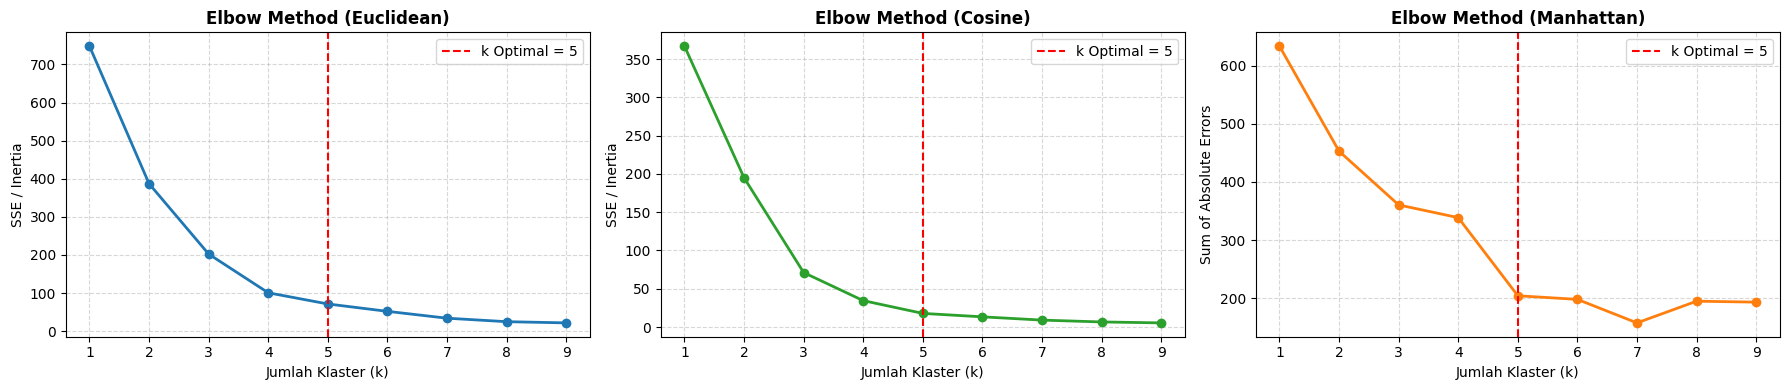

In [ ]:
K = range(1, 10)
sse_euclid = []
sse_cosine = []
sse_manhattan = []

for k in K:
    # 1. Elbow Euclidean
    km_e = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_2d)
    sse_euclid.append(km_e.inertia_)

    # 2. Elbow Cosine
    km_c = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_2d_cosine)
    sse_cosine.append(km_c.inertia_)

    # 3. Elbow Manhattan
    _, _, sse_m = kmeans_manhattan(X_2d, k=k, random_state=42)
    sse_manhattan.append(sse_m)

# ------------------------------------------------------------------------------
# VISUALISASI PLOT ELBOW (DENGAN GARIS PENENTU K OPTIMAL)
# ------------------------------------------------------------------------------
optimal_k = 5

fig_elbow, axes_elbow = plt.subplots(1, 3, figsize=(18, 4))

# Subplot 1: Euclidean
axes_elbow[0].plot(K, sse_euclid, "o-", color="tab:blue", linewidth=2)
axes_elbow[0].axvline(
    x=optimal_k,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"k Optimal = {optimal_k}",
)
axes_elbow[0].set_title("Elbow Method (Euclidean)", fontweight="bold")
axes_elbow[0].set_xlabel("Jumlah Klaster (k)")
axes_elbow[0].set_ylabel("SSE / Inertia")
axes_elbow[0].legend()
axes_elbow[0].grid(True, linestyle="--", alpha=0.5)

# Subplot 2: Cosine
axes_elbow[1].plot(K, sse_cosine, "o-", color="tab:green", linewidth=2)
axes_elbow[1].axvline(
    x=optimal_k,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"k Optimal = {optimal_k}",
)
axes_elbow[1].set_title("Elbow Method (Cosine)", fontweight="bold")
axes_elbow[1].set_xlabel("Jumlah Klaster (k)")
axes_elbow[1].set_ylabel("SSE / Inertia")
axes_elbow[1].legend()
axes_elbow[1].grid(True, linestyle="--", alpha=0.5)

# Subplot 3: Manhattan
axes_elbow[2].plot(K, sse_manhattan, "o-", color="tab:orange", linewidth=2)
axes_elbow[2].axvline(
    x=optimal_k,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"k Optimal = {optimal_k}",
)
axes_elbow[2].set_title("Elbow Method (Manhattan)", fontweight="bold")
axes_elbow[2].set_xlabel("Jumlah Klaster (k)")
axes_elbow[2].set_ylabel("Sum of Absolute Errors")
axes_elbow[2].legend()
axes_elbow[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

**Penjelasan per baris:**
* **Baris 1-4 — Inisialisasi Rentang & List** : Menentukan jumlah klaster $k$ dari 1 sampai 9 (`range(1, 10)`) dan menyiapkan list kosong untuk menampung nilai error (SSE) dari masing-masing metode.
* **Baris 6-15 — Perulangan (Looping) Elbow** : Menjalankan algoritma KMeans/K-Medians secara berulang untuk setiap nilai $k$, lalu menyimpan hasil nilai *inertia* atau SSE ke dalam list masing-masing metode.
* **Baris 19 — `optimal_k = 5`** : Menetapkan angka 5 sebagai jumlah klaster optimal yang dipilih berdasarkan bentuk kurva siku (*elbow*).
* **Baris 21 — `plt.subplots(1, 3, ...)`** : Membuat kanvas grafik yang berisi 3 kolom panel bersebelahan untuk membandingkan grafik Elbow ketiga metode secara langsung.
* **Baris 24-33 (Subplot Euclidean), 36-45 (Subplot Cosine), & 48-57 (Subplot Manhattan)** :
  * `.plot(...)` : Menggambar garis kurva penurunan nilai SSE dari $k=1$ sampai $9$.
  * `.axvline(...)` : Menambahkan garis putus-putus berwarna merah pada posisi $x = 5$ untuk mempertegas titik pemilihan klaster optimal.
  * `.set_title(...)` & `.grid(...)` : Memberikan judul pada masing-masing grafik dan menyematkan garis latar bantu (*grid*) agar mudah dibaca.

Untuk menentukan berapa jumlah kelompok atau klaster ($k$) yang paling ideal, kami menggunakan Metode Elbow (Elbow Method). Lewat perulangan dari $k=1$ hingga 9, kita menghitung nilai Sum of Squared Errors (SSE) untuk metode Euclidean, Cosine, dan Manhattan. Hasilnya divisualisasikan menjadi 3 grafik berdampingan di mana garis merah vertikal menandakan titik $k=5$, yang merupakan titik optimal tempat penurunan error mulai melandai secara signifikan

## 6. Eksekusi Model Klasterisasi (Euclidean, Cosine, & Manhattan)
Tahap ini menjalankan ketiga algoritma klasterisasi menggunakan jumlah klaster optimal (k = 5) yang sudah ditentukan sebelumnya, serta mengambil titik pusat klaster (*centroid*) dari masing-masing metode.

In [ ]:
random_state = 42

# A. EUCLIDEAN
kmeans_euclid = KMeans(
    n_clusters=optimal_k, random_state=random_state, n_init=10
)
y_euclid = kmeans_euclid.fit_predict(X_2d)
centroids_euclid = kmeans_euclid.cluster_centers_

# B. COSINE
kmeans_cosine = KMeans(
    n_clusters=optimal_k, random_state=random_state, n_init=10
)
y_cosine = kmeans_cosine.fit_predict(X_2d_cosine)
centroids_cosine = np.array(
    [X_2d[y_cosine == i].mean(axis=0) for i in range(optimal_k)]
)

# C. MANHATTAN
y_manhattan, centroids_manhattan, _ = kmeans_manhattan(
    X_2d, k=optimal_k, random_state=random_state
)

**Penjelasan per baris:**
* **Baris 1 — `random_state = 42`** : Mengatur *seed* angka acak agar inisialisasi awal titik pusat konsisten setiap kali kode dijalankan.
* **Baris 3-6 (Euclidean)** :
  * `KMeans(...)` : Menginisialisasi model KMeans standar dengan $k=5$.
  * `fit_predict(X_2d)` : Melatih model dan langsung memberikan label klaster pada data 2D.
  * `cluster_centers_` : Menyimpan koordinat titik pusat (*centroid*) dari hasil klaster Euclidean.
* **Baris 8-13 (Cosine)** :
  * `KMeans(...)` & `fit_predict(X_2d_cosine)` : Menjalankan KMeans menggunakan data yang sudah dinormalisasi L2.
  * `np.array([...])` : Menghitung ulang rata-rata koordinat asli untuk menentukan posisi pusat klaster pada metode Cosine.
* **Baris 15-17 (Manhattan)** :
  * Memanggil fungsi kustom `kmeans_manhattan` yang mengembalikan label klaster, koordinat pusat (*centroid*), dan nilai error (SSE) menggunakan metrik jarak Manhattan.

Setelah menentukan jumlah klaster optimal yaitu $k=5$, kita masuk ke tahap Eksekusi Model. Di sini kita menjalankan tiga metode secara berdampingan: Euclidean menggunakan KMeans standar, Cosine menggunakan KMeans pada data ber-normalisasi L2, dan Manhattan menggunakan fungsi kustom K-Medians. Dari setiap metode ini, kita berhasil mendapatkan label kelompok data (y) serta titik pusat klaster masing-masing (centroids) untuk dianalisis lebih lanjut

## 7. Visualisasi Hasil Klasterisasi (Scatter Plot Perbandingan)
Bagian ini berfungsi untuk membuat grafik sebar (*scatter plot*) 3 panel secara berdampingan guna memvisualisasikan bagaimana masing-masing metode (Euclidean, Cosine, dan Manhattan) mengelompokkan data beserta titik pusat klasternya (*centroid*).

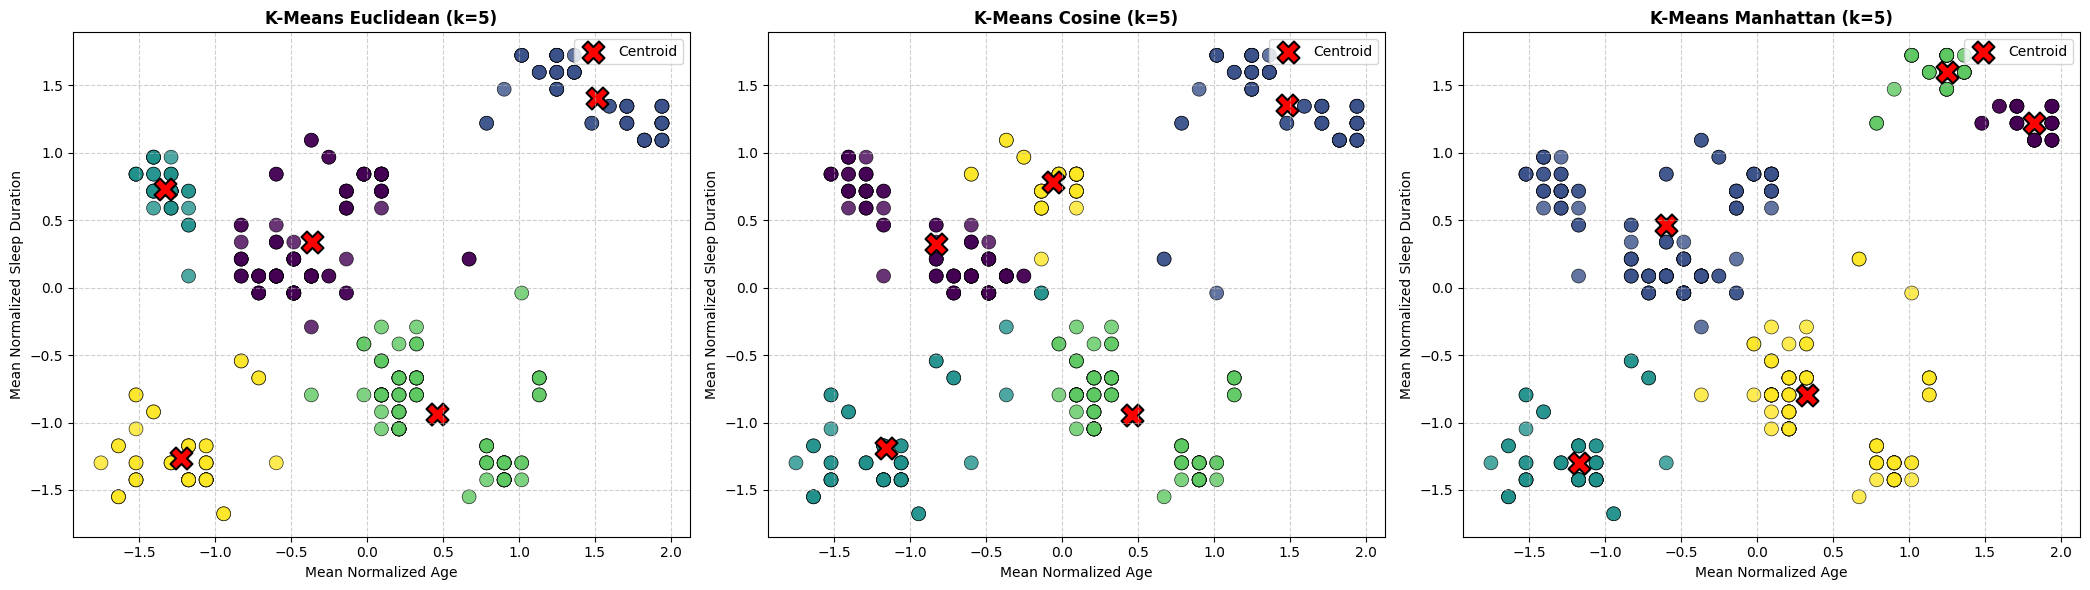

In [ ]:
fig_cluster, axes_cluster = plt.subplots(1, 3, figsize=(21, 6))

configs = [
    (
        y_euclid,
        centroids_euclid,
        f"K-Means Euclidean (k={optimal_k})",
        axes_cluster[0],
    ),
    (
        y_cosine,
        centroids_cosine,
        f"K-Means Cosine (k={optimal_k})",
        axes_cluster[1],
    ),
    (
        y_manhattan,
        centroids_manhattan,
        f"K-Means Manhattan (k={optimal_k})",
        axes_cluster[2],
    ),
]

for labels, centroids, title, ax in configs:
    ax.scatter(
        X_2d[:, 0],
        X_2d[:, 1],
        c=labels,
        cmap="viridis",
        s=100,
        alpha=0.8,
        edgecolors="k",
        linewidth=0.5,
    )

    ax.scatter(
        centroids[:, 0],
        centroids[:, 1],
        c="red",
        s=250,
        marker="X",
        label="Centroid",
        edgecolors="black",
        linewidth=1.5,
    )

    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Mean Normalized Age", fontsize=10)
    ax.set_ylabel("Mean Normalized Sleep Duration", fontsize=10)
    ax.legend(loc="upper right")
    ax.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

**Penjelasan per baris:**
* **Baris 1 — `plt.subplots(1, 3, ...)`** : Membuat satu kanvas besar berisi 3 panel subplot berdampingan secara horizontal dengan ukuran `21x6`.
* **Baris 3-20 — Variabel `configs`** : Membuat struktur list berisi konfigurasi data untuk masing-masing metode (label klaster, koordinat centroid, judul grafik, dan target sumbu *axis* grafiknya).
* **Baris 22 — `for labels, centroids, title, ax in configs:`** : Melakukan perulangan otomatis untuk menggambar grafik pada ketiga panel secara bergantian tanpa menulis kode berulang kali.
* **Baris 23-32 — `ax.scatter(...)` (Data Titik Utama)** : Memetakan data 2D berdasarkan fitur Usia dan Durasi Tidur, dengan warna titik yang dibedakan berdasarkan label klasternya (`c=labels`) menggunakan skema warna `viridis`.
* **Baris 34-43 — `ax.scatter(...)` (Titik Centroid)** : Menyimbolkan titik pusat klaster menggunakan tanda silang merah berukuran besar (`marker="X"`, warna merah `c="red"`) dengan tepi hitam agar mudah dilihat.
* **Baris 45-49 — Pengaturan Tampilan Grafik** : Memberikan judul grafik, label sumbu X dan Y, legenda (*legend*), serta garis latar belakang bantu (*grid*) dengan garis putus-putus transparan.
* **Baris 51-52 — `plt.tight_layout()` & `plt.show()`** : Merapikan tata letak agar antar grafik tidak saling tumpang tindih, lalu menampilkan hasilnya di layar.

Terakhir, untuk melihat wujud asli dari pengelompokan datanya, kami membuat Visualisasi Scatter Plot 3 Panel. Grafik ini menampilkan perbandingan bentuk klaster dari metode Euclidean, Cosine, dan Manhattan secara berdampingan. Titik-titik data diberi warna berbeda sesuai kelompoknya, lengkap dengan tanda silang merah (X) yang merepresentasikan posisi titik pusat atau centroid dari masing-masing klaster.

## 8. Benchmarking & Evaluasi Kinerja Model
Bagian ini digunakan untuk mengukur performa teknis dari ketiga metode (Euclidean, Cosine, dan Manhattan) secara objektif dengan melacak waktu eksekusi dalam milidetik, penggunaan memori puncak RAM dalam KB, serta menghitung kualitas klaster menggunakan Silhouette Score.

In [ ]:
random_state = 42
optimal_k = 5

# --- A. EUCLIDEAN ---
tracemalloc.start()
start_time = time.perf_counter()

km_e = KMeans(n_clusters=optimal_k, random_state=random_state, n_init=10)
y_euclid = km_e.fit_predict(X_2d)

time_euclid = (time.perf_counter() - start_time) * 1000  # Dalam mili saat (ms)
mem_euclid = tracemalloc.get_traced_memory()[1] / 1024  # Memori puncak dalam KB
tracemalloc.stop()

sil_euclid = silhouette_score(X_2d, y_euclid, metric="euclidean")

# --- B. COSINE ---
tracemalloc.start()
start_time = time.perf_counter()

km_c = KMeans(n_clusters=optimal_k, random_state=random_state, n_init=10)
y_cosine = km_c.fit_predict(X_2d_cosine)

time_cosine = (time.perf_counter() - start_time) * 1000  # Dalam mili saat (ms)
mem_cosine = tracemalloc.get_traced_memory()[1] / 1024  # Memori puncak dalam KB
tracemalloc.stop()

sil_cosine = silhouette_score(X_2d_cosine, y_cosine, metric="cosine")

# --- C. MANHATTAN ---
tracemalloc.start()
start_time = time.perf_counter()

y_manhattan, _, _ = kmeans_manhattan(
    X_2d, k=optimal_k, random_state=random_state
)

time_manhattan = (
    time.perf_counter() - start_time
) * 1000  # Dalam mili saat (ms)
mem_manhattan = tracemalloc.get_traced_memory()[1] / 1024  # Memori puncak dalam KB
tracemalloc.stop()

sil_manhattan = silhouette_score(X_2d, y_manhattan, metric="manhattan")

**Penjelasan per baris:**
* **Baris 1-2 — Inisialisasi Parameter** : Menetapkan `random_state = 42` untuk konsistensi hasil acak[cite: 1] dan `optimal_k = 5` sebagai jumlah klaster yang diuji[cite: 1].
* **Baris 5-6 (Euclidean) — Pelacakan Mulai** : Mengaktifkan modul pelacakan memori `tracemalloc.start()` dan mencatat waktu awal komputer menggunakan `time.perf_counter()`[cite: 1].
* **Baris 8-9 (Euclidean) — Pelatihan Model** : Menginisialisasi model KMeans standar dan menjalankan prediksi klaster (`fit_predict`) pada data 2D Euclidean[cite: 1].
* **Baris 11-13 (Euclidean) — Perhitungan Waktu & Memori** : Menghitung selisih waktu eksekusi lalu dikali 1000 untuk mengubahnya ke satuan milidetik (ms), serta mengambil data memori puncak dalam Kilobyte (KB) sebelum menghentikan pelacakan (`tracemalloc.stop()`)[cite: 1].
* **Baris 15 (Euclidean) — Evaluasi Skor** : Menghitung *Silhouette Score* untuk mengukur kualitas pemisahan klaster secara matematis berdasarkan metrik Euclidean[cite: 1].
* **Baris 18-28 (Cosine)** : Melakukan proses pengukuran performa yang serupa, namun diterapkan pada data 2D yang sudah dinormalisasi L2 (`X_2d_cosine`) dengan metrik evaluasi `"cosine"`[cite: 1].
* **Baris 31-43 (Manhattan)** : Melakukan pengukuran performa serupa dengan memanggil fungsi kustom `kmeans_manhattan` pada data asli, lalu mengevaluasi hasilnya menggunakan metrik `"manhattan"`[cite: 1].

Bagian ini adalah inti dari pengujian kuantitatif kita, yaitu Benchmarking dan Evaluasi. Untuk setiap metode (Euclidean, Cosine, dan Manhattan), kita mengukur tiga hal secara presisi: Waktu eksekusi (dalam milidetik) menggunakan time.perf_counter(), Penggunaan memori RAM (dalam Kilobyte) menggunakan modul tracemalloc, serta Silhouette Score untuk menilai seberapa rapi dan terpisah kualitas klaster yang dihasilkan secara matematis.

In [ ]:
random_state = 42
optimal_k = 5

# --- A. EUCLIDEAN ---
tracemalloc.start()
start_time = time.perf_counter()

km_e = KMeans(n_clusters=optimal_k, random_state=random_state, n_init=10)
y_euclid = km_e.fit_predict(X_2d)

time_euclid = (time.perf_counter() - start_time) * 1000  # Dalam mili saat (ms)
mem_euclid = tracemalloc.get_traced_memory()[1] / 1024  # Memori puncak dalam KB
tracemalloc.stop()

sil_euclid = silhouette_score(X_2d, y_euclid, metric="euclidean")

# --- B. COSINE ---
tracemalloc.start()
start_time = time.perf_counter()

km_c = KMeans(n_clusters=optimal_k, random_state=random_state, n_init=10)
y_cosine = km_c.fit_predict(X_2d_cosine)

time_cosine = (time.perf_counter() - start_time) * 1000  # Dalam mili saat (ms)
mem_cosine = tracemalloc.get_traced_memory()[1] / 1024  # Memori puncak dalam KB
tracemalloc.stop()

sil_cosine = silhouette_score(X_2d_cosine, y_cosine, metric="cosine")

# --- C. MANHATTAN ---
tracemalloc.start()
start_time = time.perf_counter()

y_manhattan, _, _ = kmeans_manhattan(
    X_2d, k=optimal_k, random_state=random_state
)

time_manhattan = (
    time.perf_counter() - start_time
) * 1000  # Dalam mili saat (ms)
mem_manhattan = tracemalloc.get_traced_memory()[1] / 1024  # Memori puncak dalam KB
tracemalloc.stop()

sil_manhattan = silhouette_score(X_2d, y_manhattan, metric="manhattan")

## 9. Visualisasi Grafik Perbandingan Performa (Bar Chart 2x2)
Bagian ini berfungsi untuk merangkum dan memvisualisasikan seluruh hasil pengujian metrik (jumlah klaster, waktu eksekusi, penggunaan memori RAM, dan Silhouette Score) ke dalam grafik batang 2x2 agar perbandingan antar metode dapat dilihat secara jelas dan komparatif.

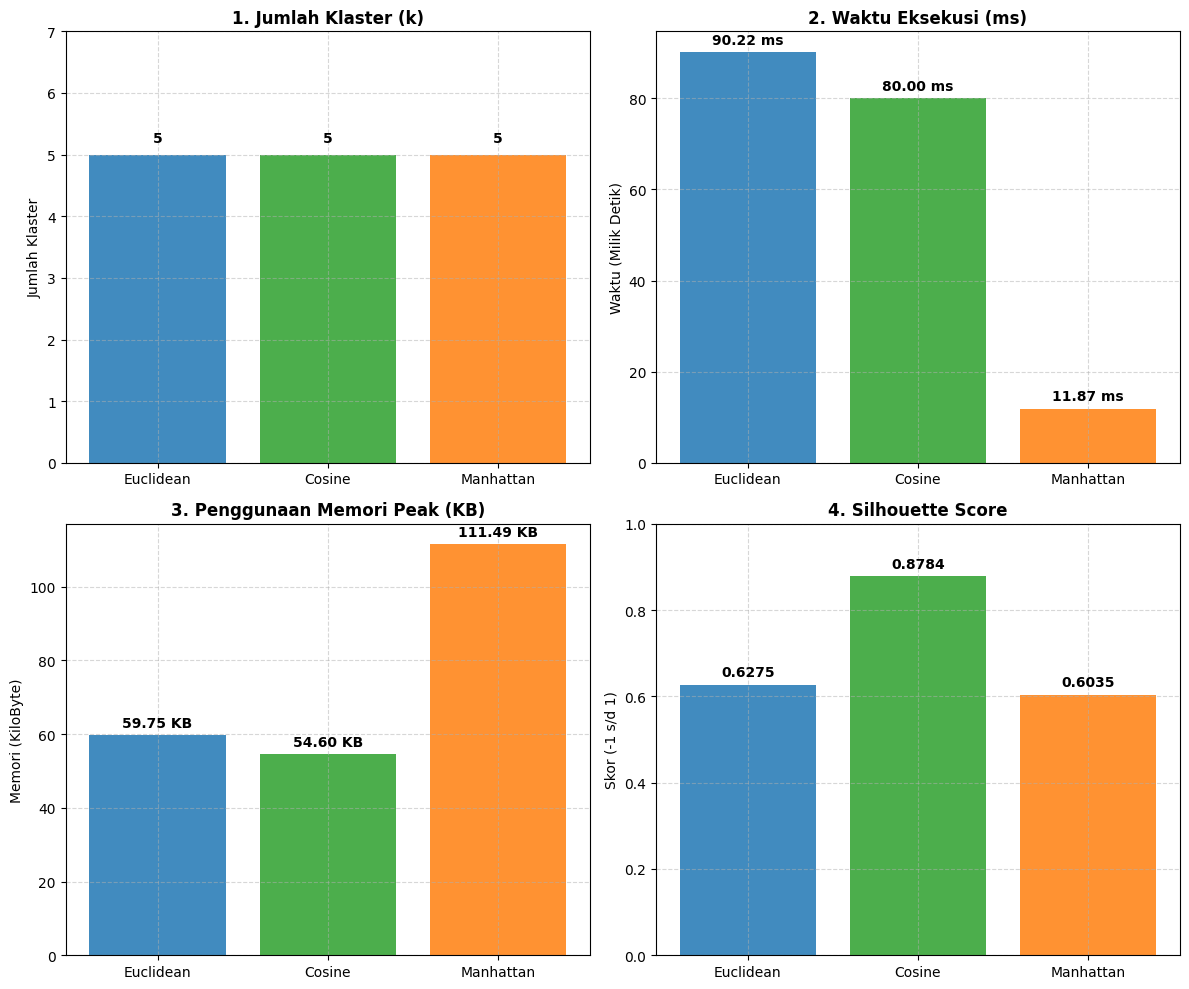

In [ ]:
methods = ["Euclidean", "Cosine", "Manhattan"]
counts = [
    len(np.unique(y_euclid)),
    len(np.unique(y_cosine)),
    len(np.unique(y_manhattan)),
]
times = [time_euclid, time_cosine, time_manhattan]
mems = [mem_euclid, mem_cosine, mem_manhattan]
silhouettes = [sil_euclid, sil_cosine, sil_manhattan]

colors = ["tab:blue", "tab:green", "tab:orange"]

fig_metrics, axes_m = plt.subplots(2, 2, figsize=(12, 10))

# Subplot 1: Jumlah Klaster
axes_m[0, 0].bar(methods, counts, color=colors, alpha=0.85)
axes_m[0, 0].set_title("1. Jumlah Klaster (k)", fontweight="bold")
axes_m[0, 0].set_ylabel("Jumlah Klaster")
axes_m[0, 0].set_ylim(0, max(counts) + 2)
for i, v in enumerate(counts):
    axes_m[0, 0].text(i, v + 0.2, str(v), ha="center", fontweight="bold")

# Subplot 2: Waktu Eksekusi
axes_m[0, 1].bar(methods, times, color=colors, alpha=0.85)
axes_m[0, 1].set_title("2. Waktu Eksekusi (ms)", fontweight="bold")
axes_m[0, 1].set_ylabel("Waktu (Milik Detik)")
for i, v in enumerate(times):
    axes_m[0, 1].text(
        i, v + max(times) * 0.02, f"{v:.2f} ms", ha="center", fontweight="bold"
    )

# Subplot 3: Penggunaan Memori
axes_m[1, 0].bar(methods, mems, color=colors, alpha=0.85)
axes_m[1, 0].set_title("3. Penggunaan Memori Peak (KB)", fontweight="bold")
axes_m[1, 0].set_ylabel("Memori (KiloByte)")
for i, v in enumerate(mems):
    axes_m[1, 0].text(
        i, v + max(mems) * 0.02, f"{v:.2f} KB", ha="center", fontweight="bold"
    )

# Subplot 4: Silhouette Score
axes_m[1, 1].bar(methods, silhouettes, color=colors, alpha=0.85)
axes_m[1, 1].set_title("4. Silhouette Score", fontweight="bold")
axes_m[1, 1].set_ylabel("Skor (-1 s/d 1)")
axes_m[1, 1].set_ylim(0, 1.0)
for i, v in enumerate(silhouettes):
    axes_m[1, 1].text(i, v + 0.02, f"{v:.4f}", ha="center", fontweight="bold")

for ax_row in axes_m:
    for ax in ax_row:
        ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

**Penjelasan per baris:**
* **Baris 1-7 — Penyiapan Data Metrik** : Membuat list variabel `methods` (nama metode), `counts` (jumlah klaster unik), `times` (waktu eksekusi), `mems` (memori), dan `silhouettes` (skor kualitas) yang diambil dari hasil pengujian sebelumnya.
* **Baris 9 — `colors = [...]`** : Menentukan warna khusus untuk masing-masing metode (biru untuk Euclidean, hijau untuk Cosine, dan oranye untuk Manhattan).
* **Baris 11 — `plt.subplots(2, 2, ...)`** : Membuat kanvas berisi 4 panel grafik berukuran 2 baris dan 2 kolom (`figsize=(12, 10)`).
* **Baris 13-19 (Subplot 1 - Jumlah Klaster)** : Menggambar diagram batang jumlah klaster per metode lengkap dengan teks angka di atas batangnya (`axes_m[0, 0].text`).
* **Baris 21-28 (Subplot 2 - Waktu Eksekusi)** : Menggambar diagram batang untuk membandingkan kecepatan waktu eksekusi dalam satuan milidetik (ms).
* **Baris 30-37 (Subplot 3 - Penggunaan Memori)** : Menggambar diagram batang untuk melihat seberapa besar penggunaan memori puncak RAM dalam Kilobyte (KB).
* **Baris 39-46 (Subplot 4 - Silhouette Score)** : Menggambar diagram batang skor kualitas pemisahan klaster dengan batas nilai maksimum sumbu Y diatur hingga 1.0.
* **Baris 48-50 — Penambahan Grid** : Menyematkan garis latar bantu putus-putus (`grid`) pada seluruh panel grafik agar pembacaan data menjadi lebih mudah.
* **Baris 52-53 — `plt.tight_layout()` & `plt.show()`** : Merapikan keseluruhan tata letak antar grafik dan menampilkan visualisasinya ke layar.

Sebagai penutup dari kode analisis ini, kami membuat Grafik Perbandingan Performa 2x2. Grafik batang ini merangkum empat parameter penting secara berdampingan: jumlah klaster yang terbentuk, waktu eksekusi dalam milidetik, penggunaan memori RAM dalam Kilobyte, serta skor kualitas Silhouette. Melalui visualisasi ini, kita dapat menarik kesimpulan objektif mengenai kelebihan dan kekurangan dari masing-masing metrik jarak (Euclidean, Cosine, dan Manhattan) yang telah diuji

<p align ="center">
   ======== ANALISIS ========
</p>
Berdasarkan hasil evaluasi komparatif pada kelima klaster ($k=5$), model Euclidean Distance merupakan pilihan terbaik dan paling direkomendasikan untuk digunakan. Model ini menghasilkan Silhouette Score sebesar 0.6275 yang valid untuk mengelompokkan data spasial 2D secara seimbang, intuitif, dan rapi, serta didukung penggunaan memori yang efisien yaitu 59.27 KB.   Sebagai alternatif, Manhattan Distance dapat dipilih jika prioritas utama sistem adalah kecepatan pemrosesan, karena memiliki waktu eksekusi paling cepat yaitu 8.00 ms dengan kualitas klaster yang tetap valid (Silhouette Score 0.6035), meskipun membutuhkan konsumsi memori lebih tinggi sebesar 111.49 KB.   Sementara itu, Cosine Distance sangat tidak direkomendasikan meskipun memiliki Silhouette Score tertinggi sebesar 0.8784. Nilai tersebut bersifat semu (misleading) akibat kecenderungan Cosine yang mengelompokkan mayoritas data ke dalam satu klaster utama dan menganggap titik lainnya sebagai pencilan, sehingga tidak cocok untuk jenis data ini.